# Pricing and revenue management: from price-response estimation to optimal (segmented and dynamic) prices

**Question:** how does demand for an online product respond to price, and what prices maximise profit?
1. with a single price;
2. when the market can be split into segments (with cannibalisation);
3. when prices can vary by day of the week;
4. when capacity is limited, as in a 400-seat theatre.

**Data:** a 151-day price experiment (Jan – May 2022) for one item sold online. Each day records:
- the price and sales (realised demand);
- the **potential demand** (visitors, from click data);
- day of the week, a competitor's price and whether it rained.

The first 114 days (≈ 75%) are used for estimation, and the last 37 days for testing.

**Contents**
- **A.** Price-response functions (linear, exponential, logit)
- **B.** Conversion-rate models and potential demand
- **C.** Optimal single price
- **D.** Market segmentation and cannibalisation
- **E.** Day-of-week (variable) pricing
- **F.** Capacity-constrained pricing: the theatre

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import gurobipy as gp
from gurobipy import GRB

data = pd.read_csv(Path("data") / "HW1data.csv", index_col=0, encoding="utf-8-sig")
data = data.rename(columns={"Compatitors_Price": "Competitor_Price"})
N_TRAIN = 114
train, test = data.iloc[:N_TRAIN].copy(), data.iloc[N_TRAIN:].copy()
for d in (train, test):
    d["CR"] = d["Sales"] / d["Potential_Demand"]           # conversion rate r = d / D
    d["Fri"] = 1 - d[["Sat", "Sun", "Mon", "Tue", "Wed", "Thu"]].sum(axis=1)

print(f"{len(data)} days | train {len(train)} | test {len(test)}")
print(data.describe().round(1).T[["mean", "min", "max"]].to_string())

def errors(actual, predicted):
    e = np.asarray(actual, float) - np.asarray(predicted, float)
    return {"RMSE": float(np.sqrt(np.mean(e ** 2))), "MAPE (%)": float(np.mean(np.abs(e / np.asarray(actual))) * 100)}

results = {}                                              # collects train/test errors of every sales model
def record(name, pred_train, pred_test, target="Sales"):
    results[name] = {"train RMSE": errors(train[target], pred_train)["RMSE"],
                     "train MAPE (%)": errors(train[target], pred_train)["MAPE (%)"],
                     "test RMSE": errors(test[target], pred_test)["RMSE"],
                     "test MAPE (%)": errors(test[target], pred_test)["MAPE (%)"]}
    print(name, {k: round(v, 2) for k, v in results[name].items()})

151 days | train 114 | test 37
                   mean   min    max
Sales              47.8  15.0  102.0
Price             103.3  95.0  115.0
Potential_Demand   69.1  23.0  130.0
Sat                 0.1   0.0    1.0
Sun                 0.1   0.0    1.0
Mon                 0.1   0.0    1.0
Tue                 0.1   0.0    1.0
Wed                 0.1   0.0    1.0
Thu                 0.1   0.0    1.0
Rain                0.2   0.0    1.0
Competitor_Price  102.0  90.0  110.0


## A. Price-response functions estimated from price and sales only
| Model | Form | Estimated by |
|---|---|---|
| Linear | d(p) = D − bp | OLS of sales on price |
| Exponential | d(p) = D·e^(−bp) | OLS of log(sales) on price |
| Logit | d(p) = D̂ · e^(a+bp) / (1 + e^(a+bp)) | OLS of log-odds of the conversion rate on price; D̂ = average potential demand (training data) |

In [2]:
lin = smf.ols("Sales ~ Price", train).fit()
expo = smf.ols("np.log(Sales) ~ Price", train).fit()
logit = smf.ols("np.log(CR / (1 - CR)) ~ Price", train).fit()
D_hat = train["Potential_Demand"].mean()

D_lin, b_lin = lin.params["Intercept"], -lin.params["Price"]
D_exp, b_exp = np.exp(expo.params["Intercept"]), -expo.params["Price"]
a_log, b_log = logit.params["Intercept"], logit.params["Price"]

def d_linear(p): return np.maximum(D_lin - b_lin * p, 0)
def d_expo(p): return D_exp * np.exp(-b_exp * p)
def d_logit(p): return D_hat * np.exp(a_log + b_log * p) / (1 + np.exp(a_log + b_log * p))

print(f"Linear:      d(p) = {D_lin:.2f} - {b_lin:.4f} p        R² = {lin.rsquared:.3f}, price p = {lin.pvalues['Price']:.1e}")
print(f"Exponential: d(p) = {D_exp:.1f} · exp(-{b_exp:.4f} p)   R² = {expo.rsquared:.3f}, price p = {expo.pvalues['Price']:.1e}")
print(f"Logit:       d(p) = {D_hat:.1f} · logistic({a_log:.3f} {b_log:+.4f} p)   R² (log-odds) = {logit.rsquared:.3f}")
print()
record("A. Linear", d_linear(train["Price"]), d_linear(test["Price"]))
record("A. Exponential", d_expo(train["Price"]), d_expo(test["Price"]))
record("A. Logit (average D)", d_logit(train["Price"]), d_logit(test["Price"]))

Linear:      d(p) = 203.06 - 1.4990 p        R² = 0.216, price p = 1.9e-07
Exponential: d(p) = 1291.8 · exp(-0.0324 p)   R² = 0.230, price p = 7.0e-08
Logit:       d(p) = 69.5 · logistic(7.421 -0.0638 p)   R² (log-odds) = 0.791

A. Linear {'train RMSE': 14.65, 'train MAPE (%)': 26.86, 'test RMSE': 12.5, 'test MAPE (%)': 23.97}
A. Exponential {'train RMSE': 14.75, 'train MAPE (%)': 25.18, 'test RMSE': 12.5, 'test MAPE (%)': 22.57}
A. Logit (average D) {'train RMSE': 14.97, 'train MAPE (%)': 27.31, 'test RMSE': 12.2, 'test MAPE (%)': 24.83}


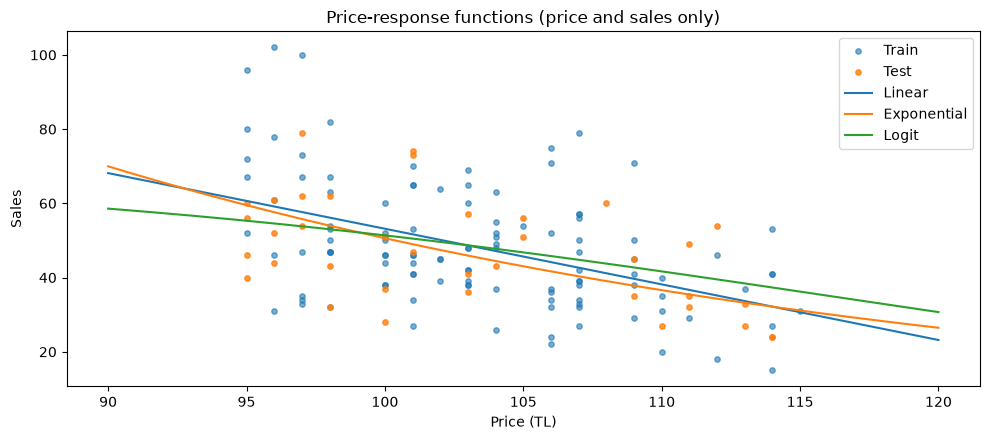

In [3]:
grid = np.linspace(data["Price"].min() - 5, data["Price"].max() + 5, 200)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.scatter(train["Price"], train["Sales"], s=15, alpha=0.6, label="Train")
ax.scatter(test["Price"], test["Sales"], s=15, alpha=0.8, label="Test")
for f, name in [(d_linear, "Linear"), (d_expo, "Exponential"), (d_logit, "Logit")]:
    ax.plot(grid, f(grid), label=name)
ax.set_xlabel("Price (TL)"); ax.set_ylabel("Sales"); ax.set_title("Price-response functions (price and sales only)")
ax.legend(); plt.tight_layout(); plt.show()

Price on its own explains only about a fifth of the variation in sales (R² ≈ 0.22): the sales errors are around 25%. Much of the day-to-day variation comes from how many people visit, which section B models explicitly.

## B. Conversion-rate models and potential demand
The **conversion rate** r = sales ÷ potential demand isolates the effect of price on the share of visitors who buy. When potential demand is known, sales = D_j · r̂(p_j).

In [4]:
cr_lin = smf.ols("CR ~ Price", train).fit()
cr_exp = smf.ols("np.log(CR) ~ Price", train).fit()
cr_logit = logit                                   # same log-odds regression as in A

def r_linear(p): return cr_lin.params["Intercept"] + cr_lin.params["Price"] * p
def r_expo(p): return np.exp(cr_exp.params["Intercept"] + cr_exp.params["Price"] * p)
def r_logit(p): return 1 / (1 + np.exp(-(a_log + b_log * p)))

for name, model in [("linear", cr_lin), ("exponential", cr_exp), ("logit", cr_logit)]:
    print(f"Conversion rate, {name:11s}: R² = {model.rsquared:.3f}, price coefficient {model.params['Price']:+.5f} (p = {model.pvalues['Price']:.1e})")
print()
for name, r in [("B. CR linear x known D", r_linear), ("B. CR exponential x known D", r_expo), ("B. CR logit x known D", r_logit)]:
    record(name, train["Potential_Demand"] * r(train["Price"]), test["Potential_Demand"] * r(test["Price"]))

Conversion rate, linear     : R² = 0.795, price coefficient -0.01352 (p = 2.7e-40)
Conversion rate, exponential: R² = 0.788, price coefficient -0.02024 (p = 1.5e-39)
Conversion rate, logit      : R² = 0.791, price coefficient -0.06379 (p = 7.6e-40)

B. CR linear x known D {'train RMSE': 1.92, 'train MAPE (%)': 3.75, 'test RMSE': 2.25, 'test MAPE (%)': 4.36}
B. CR exponential x known D {'train RMSE': 1.92, 'train MAPE (%)': 3.74, 'test RMSE': 2.32, 'test MAPE (%)': 4.43}
B. CR logit x known D {'train RMSE': 1.97, 'train MAPE (%)': 3.88, 'test RMSE': 2.2, 'test MAPE (%)': 4.27}


With the actual potential demand known, the errors drop from ~25% to ~4%: price explains the **conversion rate** very well (R² ≈ 0.79). In practice, though, potential demand is not known in advance, so it has to be forecast.

**Potential demand** is regressed on the day of the week (Friday = reference), rain and the competitor's price. Insignificant predictors are then removed.

In [5]:
pd_full = smf.ols("Potential_Demand ~ Sat + Sun + Mon + Tue + Wed + Thu + Rain + Competitor_Price", train).fit()
print(pd_full.summary().tables[1])
significant = [v for v in pd_full.pvalues.index if v != "Intercept" and pd_full.pvalues[v] < 0.05]
pd_red = smf.ols("Potential_Demand ~ " + " + ".join(significant), train).fit()
print("Reduced model:", "Potential_Demand ~ " + " + ".join(significant))
print(f"R² full = {pd_full.rsquared:.3f} | reduced = {pd_red.rsquared:.3f} (adj. {pd_full.rsquared_adj:.3f} vs {pd_red.rsquared_adj:.3f})")
D_train_hat, D_test_hat = pd_red.predict(train), pd_red.predict(test)
record("B. Potential demand (reduced regression)", D_train_hat, D_test_hat, target="Potential_Demand")

                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           91.3743     15.355      5.951      0.000      60.929     121.820
Sat                 26.0879      3.924      6.648      0.000      18.307      33.869
Sun                 20.1626      3.846      5.242      0.000      12.536      27.789
Mon                  2.2349      3.896      0.574      0.567      -5.490       9.959
Tue                 -5.0471      3.897     -1.295      0.198     -12.775       2.681
Wed                 -4.5471      3.897     -1.167      0.246     -12.275       3.181
Thu                 -3.0695      3.993     -0.769      0.444     -10.988       4.849
Rain                33.0897      2.911     11.366      0.000      27.317      38.862
Competitor_Price    -0.3332      0.151     -2.209      0.029      -0.632      -0.034
Reduced model: Potential_Demand ~ Sat + Sun + Rain + Competitor_P

**Combined sales forecast:** forecast potential demand × the best conversion-rate model. The CR model is chosen on **training** error, so the test set is not used for the choice.

In [6]:
cr_models = {"linear": r_linear, "exponential": r_expo, "logit": r_logit}
best_cr = min(cr_models, key=lambda k: results[[n for n in results if k in n and "known" in n][0]]["train RMSE"])
r_best = cr_models[best_cr]
print("Best conversion-rate model on training data:", best_cr)
record(f"B. Forecast D x CR {best_cr}", D_train_hat * r_best(train["Price"]), D_test_hat * r_best(test["Price"]))

summary = pd.DataFrame(results).T
print()
print(summary.round(2).to_string())

Best conversion-rate model on training data: linear
B. Forecast D x CR linear {'train RMSE': 7.54, 'train MAPE (%)': 15.62, 'test RMSE': 7.21, 'test MAPE (%)': 12.66}

                                          train RMSE  train MAPE (%)  test RMSE  test MAPE (%)
A. Linear                                      14.65           26.86      12.50          23.97
A. Exponential                                 14.75           25.18      12.50          22.57
A. Logit (average D)                           14.97           27.31      12.20          24.83
B. CR linear x known D                          1.92            3.75       2.25           4.36
B. CR exponential x known D                     1.92            3.74       2.32           4.43
B. CR logit x known D                           1.97            3.88       2.20           4.27
B. Potential demand (reduced regression)       10.81           15.38      10.41          13.76
B. Forecast D x CR linear                       7.54           15.62    

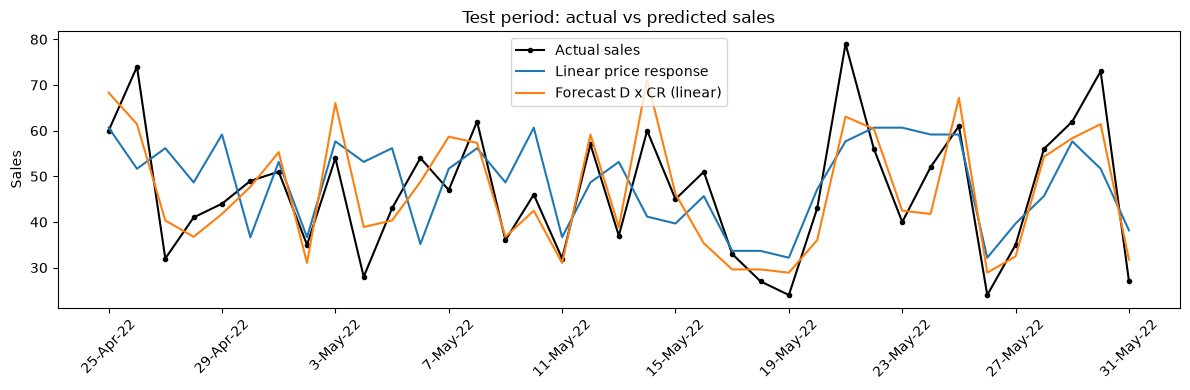

In [7]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(test.index, test["Sales"], "k-o", ms=3, label="Actual sales")
ax.plot(test.index, d_linear(test["Price"]), label="Linear price response")
ax.plot(test.index, D_test_hat * r_best(test["Price"]), label=f"Forecast D x CR ({best_cr})")
ax.set_xticks(test.index[::4]); ax.tick_params(axis="x", rotation=45)
ax.set_ylabel("Sales"); ax.set_title("Test period: actual vs predicted sales"); ax.legend()
plt.tight_layout(); plt.show()

## C. Optimal single price
For each price-response model from A, the profit m(p) = (p − c)·d(p) is maximised for incremental costs c = 0, 10, 20, 30 TL. This is a fine grid search, which also covers the logit model (no closed form). For reference, the closed forms are p* = (D/b + c)/2 for the linear model and p* = 1/b + c for the exponential model.

In [8]:
price_grid = np.arange(0, 200.01, 0.01)
rows = []
for c in [0, 10, 20, 30]:
    for name, f in [("Linear", d_linear), ("Exponential", d_expo), ("Logit", d_logit)]:
        profit = (price_grid - c) * f(price_grid)
        i = profit.argmax()
        p_star = price_grid[i]
        rows.append({"cost c": c, "model": name, "p*": p_star, "d(p*)": f(p_star),
                     "revenue": p_star * f(p_star), "profit": profit[i]})
opt = pd.DataFrame(rows)
print(opt.round(2).to_string(index=False))
print(f"\nCheck, closed forms at c = 30: linear {(D_lin / b_lin + 30) / 2:.2f} | exponential {1 / b_exp + 30:.2f}")
print(f"Prices tested in the experiment: {data['Price'].min()}–{data['Price'].max()} TL")

 cost c       model    p*  d(p*)  revenue   profit
      0      Linear 67.73 101.53  6876.74  6876.74
      0 Exponential 30.87 475.20 14669.43 14669.43
      0       Logit 91.60  57.61  5276.68  5276.68
     10      Linear 72.73  94.04  6839.29  5898.92
     10 Exponential 40.87 343.70 14047.00 10610.01
     10       Logit 93.39  56.44  5270.68  4706.31
     20      Linear 77.73  86.54  6726.89  4996.05
     20 Exponential 50.87 248.59 12645.71  7673.93
     20       Logit 95.37  55.04  5249.59  4148.70
     30      Linear 82.73  79.05  6539.53  4168.13
     30 Exponential 60.87 179.80 10944.28  5550.35
     30       Logit 97.57  53.37  5207.50  3606.34

Check, closed forms at c = 30: linear 82.73 | exponential 60.87
Prices tested in the experiment: 95–115 TL


**Caution, extrapolation.** The linear and exponential optima (≈ 61–83 TL at c = 30) lie **far below the prices actually tested (95–115 TL)**. Those models are only estimated within that range, and the exponential model in particular explodes at low prices (475 units at 31 TL, against at most 130 visitors a day). The logit model is bounded by the potential demand, which makes it the most credible: its optimum (≈ 92–98 TL) sits at the edge of the tested range. A follow-up price test around 85–100 TL would settle the question.

## D. Market segmentation and cannibalisation
Suppose the seller can split the market at a willingness-to-pay of **60 TL**, using the linear price response d(p) = D − bp:
- **High segment** (WTP ≥ 60): demand d_H(p) = D − bp for p ≥ 60.
- **Low segment** (WTP < 60): demand d_L(p) = d(p) − d(60) = b(60 − p) for p ≤ 60.

With **cannibalisation rate α**, a share α of high-segment customers buys at the low price instead:

d_H(p_H) = (1 − α)(D − b·p_H), d_L(p_L) = b(60 − p_L) + α·d(60).

Profit (p_H − 30)·d_H + (p_L − 30)·d_L is maximised with Gurobi (a non-convex quadratic objective), with p_H ≥ 60 ≥ p_L.

In [9]:
COST, THRESHOLD = 30, 60
d60 = D_lin - b_lin * THRESHOLD

def segmented_prices(alpha):
    m = gp.Model("segmentation"); m.Params.OutputFlag = 0; m.Params.NonConvex = 2
    pH = m.addVar(lb=THRESHOLD, ub=D_lin / b_lin, name="p_high")
    pL = m.addVar(lb=0, ub=THRESHOLD, name="p_low")
    qH = m.addVar(lb=0, name="q_high"); qL = m.addVar(lb=0, name="q_low")
    m.addConstr(qH <= (1 - alpha) * (D_lin - b_lin * pH))
    m.addConstr(qL <= b_lin * (THRESHOLD - pL) + alpha * d60)
    m.setObjective((pH - COST) * qH + (pL - COST) * qL, GRB.MAXIMIZE)
    m.optimize()
    return {"alpha": alpha, "p_high": pH.X, "p_low": pL.X, "q_high": qH.X, "q_low": qL.X, "profit": m.ObjVal}

single = opt.query("model == 'Linear' and `cost c` == 30").iloc[0]
seg = pd.DataFrame([segmented_prices(a) for a in [0, 0.1, 0.2, 0.3, 0.5, 0.7]])
print(f"Single price (no segmentation): p* = {single['p*']:.2f} TL, profit = {single['profit']:.0f} TL")
print(seg.round(2).to_string(index=False))
fine = np.arange(0, 0.5, 0.005)
fine_profit = np.array([segmented_prices(a)["profit"] for a in fine])
break_even = fine[np.argmax(fine_profit < single["profit"])]
print(f"\nSegmentation beats the single price only while alpha < {break_even:.3f}")

Restricted license - for non-production use only - expires 2027-11-29


Single price (no segmentation): p* = 82.73 TL, profit = 4168 TL
 alpha  p_high  p_low  q_high  q_low  profit
   0.0   82.73  45.00   79.04  22.49 4505.41
   0.1   82.73  48.77   71.14  28.14 4279.61
   0.2   82.73  52.55   63.24  33.80 4096.50
   0.3   82.73  56.32   55.33  39.45 3956.07
   0.5   82.73  60.00   39.52  56.56 3780.85
   0.7   82.73  60.00   23.71  79.18 3625.94



Segmentation beats the single price only while alpha < 0.160


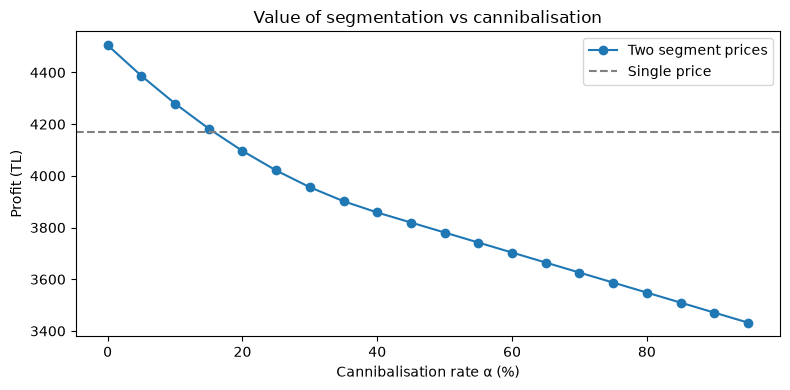

In [10]:
alphas = np.arange(0, 1.0, 0.05)
curve = [segmented_prices(a)["profit"] for a in alphas]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(alphas * 100, curve, "o-", label="Two segment prices")
ax.axhline(single["profit"], color="grey", linestyle="--", label="Single price")
ax.set_xlabel("Cannibalisation rate α (%)"); ax.set_ylabel("Profit (TL)")
ax.set_title("Value of segmentation vs cannibalisation"); ax.legend(); plt.tight_layout(); plt.show()

## E. Day-of-week (variable) pricing
The price response now includes day-of-week indicators, *d(p) = a − b·p + Σ day effects* (Friday = reference). After the full fit, only significant day effects are kept. Each day's price then maximises (p − 30)·d_day(p), which is solved jointly for the seven days.

In [11]:
dow_full = smf.ols("Sales ~ Price + Sat + Sun + Mon + Tue + Wed + Thu", train).fit()
print(dow_full.summary().tables[1])
sig_days = [v for v in ["Sat", "Sun", "Mon", "Tue", "Wed", "Thu"] if dow_full.pvalues[v] < 0.05]
dow = smf.ols("Sales ~ Price + " + " + ".join(sig_days), train).fit()
print("Reduced model:", "Sales ~ Price + " + " + ".join(sig_days), f"| R² {dow_full.rsquared:.3f} -> {dow.rsquared:.3f}")
record("E. Day-of-week linear (reduced)", dow.predict(train), dow.predict(test))

DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
a_dow, b_dow = dow.params["Intercept"], -dow.params["Price"]
intercepts = {day: a_dow + dow.params.get(day, 0.0) for day in DAYS}

m = gp.Model("day_of_week"); m.Params.OutputFlag = 0; m.Params.NonConvex = 2
price = m.addVars(DAYS, lb=0, name="price"); qty = m.addVars(DAYS, lb=0, name="qty")
m.addConstrs(qty[d] <= intercepts[d] - b_dow * price[d] for d in DAYS)
m.setObjective(gp.quicksum((price[d] - COST) * qty[d] for d in DAYS), GRB.MAXIMIZE)
m.optimize()
variable = pd.DataFrame({"intercept": intercepts, "price": {d: price[d].X for d in DAYS},
                         "sales": {d: qty[d].X for d in DAYS}}).assign(profit=lambda t: (t["price"] - COST) * t["sales"])

# Best single price under the same model, for comparison
p_single = (np.mean(list(intercepts.values())) / b_dow + COST) / 2
single_profit = sum((p_single - COST) * max(intercepts[d] - b_dow * p_single, 0) for d in DAYS)
print(variable.round(2).to_string())
print(f"\nWeekly profit: variable pricing {variable['profit'].sum():,.0f} TL vs single price "
      f"({p_single:.2f} TL) {single_profit:,.0f} TL (+{variable['profit'].sum() / single_profit - 1:.1%})")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    172.0881     23.141      7.436      0.000     126.209     217.967
Price         -1.2522      0.223     -5.615      0.000      -1.694      -0.810
Sat           23.5909      4.090      5.768      0.000      15.482      31.700
Sun           14.6295      4.067      3.597      0.000       6.567      22.692
Mon           -0.3407      4.124     -0.083      0.934      -8.516       7.835
Tue           -2.1836      4.131     -0.529      0.598     -10.373       6.006
Wed           -3.7055      4.119     -0.900      0.370     -11.872       4.461
Thu            4.6131      4.129      1.117      0.266      -3.574      12.800
Reduced model: Sales ~ Price + Sat + Sun | R² 0.541 -> 0.521
E. Day-of-week linear (reduced) {'train RMSE': 11.46, 'train MAPE (%)': 20.56, 'test RMSE': 11.26, 'test MAPE (%)': 18.83}


     intercept  price  sales   profit
Mon     166.67  84.27  65.29  3543.12
Tue     166.67  84.27  65.29  3543.12
Wed     166.67  84.27  65.29  3543.12
Thu     166.67  84.27  65.29  3543.12
Fri     166.67  84.27  65.29  3543.12
Sat     190.75  94.27  77.33  4970.03
Sun     181.59  90.46  72.75  4398.52

Weekly profit: variable pricing 27,084 TL vs single price (86.58 TL) 26,963 TL (+0.5%)


## F. Capacity-constrained pricing: a 400-seat theatre
One performance a day; the daily price responses are given (TL):

| Sun | Mon | Tue | Wed | Thu | Fri | Sat |
|---|---|---|---|---|---|---|
| 1000 − 2p | 400 − 2p | 600 − 2p | 700 − 2p | 800 − 2p | 1800 − 4p | 2000 − 4p |

Four pricing policies are compared on weekly revenue:
- **(a)** a single price;
- **(b)** a different price each day;
- **(c)** two prices (Fri–Sun vs Mon–Thu);
- **(d)** two prices where weekend customers **divert** to weekdays at 0.5 customers per TL of price difference, spread evenly over the four weekdays.

In [12]:
THEATRE = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
D0 = dict(zip(THEATRE, [1000, 400, 600, 700, 800, 1800, 2000]))
SLOPE = dict(zip(THEATRE, [2, 2, 2, 2, 2, 4, 4]))
CAPACITY = 400
WEEKEND = ["Fri", "Sat", "Sun"]; WEEKDAY = ["Mon", "Tue", "Wed", "Thu"]

def theatre(policy, diversion=0.0):
    m = gp.Model(policy); m.Params.OutputFlag = 0; m.Params.NonConvex = 2
    if policy == "single":
        p = m.addVar(lb=0); price = {d: p for d in THEATRE}
    elif policy == "daily":
        pv = m.addVars(THEATRE, lb=0); price = {d: pv[d] for d in THEATRE}
    else:  # two prices
        pw, pd_ = m.addVar(lb=0, name="weekend"), m.addVar(lb=0, name="weekday")
        price = {d: (pw if d in WEEKEND else pd_) for d in THEATRE}
    q = m.addVars(THEATRE, lb=0, ub=CAPACITY)
    for d in THEATRE:
        demand = D0[d] - SLOPE[d] * price[d]
        if diversion:
            gap = price["Fri"] - price["Mon"]           # weekend price - weekday price
            demand = demand - diversion * gap if d in WEEKEND else demand + diversion * gap * len(WEEKEND) / len(WEEKDAY)
        m.addConstr(q[d] <= demand)
    m.setObjective(gp.quicksum(price[d] * q[d] for d in THEATRE), GRB.MAXIMIZE)
    m.optimize()
    return pd.DataFrame({"price": {d: price[d].X for d in THEATRE}, "seats sold": {d: q[d].X for d in THEATRE}}) \
             .assign(revenue=lambda t: t["price"] * t["seats sold"])

policies = {"(a) single price": theatre("single"), "(b) daily prices": theatre("daily"),
            "(c) two prices": theatre("two"), "(d) two prices + diversion": theatre("two", diversion=0.5)}
for name, t in policies.items():
    print(f"{name}: weekly revenue {t['revenue'].sum():,.0f} TL")
    print(t.round(1).T.to_string()); print()

(a) single price: weekly revenue 420,000 TL
                Sun    Mon      Tue      Wed      Thu      Fri      Sat
price         200.0  200.0    200.0    200.0    200.0    200.0    200.0
seats sold    400.0    0.0    200.0    300.0    400.0    400.0    400.0
revenue     80000.0    0.0  40000.0  60000.0  80000.0  80000.0  80000.0

(b) daily prices: weekly revenue 626,250 TL
                 Sun      Mon      Tue      Wed      Thu       Fri       Sat
price          300.0    100.0    150.0    175.0    200.0     350.0     400.0
seats sold     400.0    200.0    300.0    350.0    400.0     400.0     400.0
revenue     120000.0  20000.0  45000.0  61250.0  80000.0  140000.0  160000.0

(c) two prices: weekly revenue 568,750 TL
                 Sun     Mon      Tue      Wed      Thu       Fri       Sat
price          350.0   175.0    175.0    175.0    175.0     350.0     350.0
seats sold     300.0    50.0    250.0    350.0    400.0     400.0     400.0
revenue     105000.0  8750.0  43750.0  61250

In [13]:
rev = pd.Series({k: v["revenue"].sum() for k, v in policies.items()})
util = pd.Series({k: v["seats sold"].sum() / (CAPACITY * 7) for k, v in policies.items()})
print(pd.DataFrame({"weekly revenue (TL)": rev.round(0), "vs single price": (rev / rev.iloc[0] - 1).map("{:+.1%}".format),
                    "seat utilisation": util.map("{:.0%}".format)}).to_string())

                            weekly revenue (TL) vs single price seat utilisation
(a) single price                       420000.0           +0.0%              75%
(b) daily prices                       626250.0          +49.1%              87%
(c) two prices                         568750.0          +35.4%              77%
(d) two prices + diversion             566444.0          +34.9%              78%


## Summary
- **Estimation:** the forecast that combines potential demand with the conversion rate halves the test error of a price-only model (MAPE ≈ 13% vs ≈ 24%).
- **Single price:** the three price-response models disagree strongly once they are used outside the tested price range. The logit model, bounded by potential demand, gives the most credible optimum (≈ 98 TL at 30 TL cost). The linear and exponential optima are extrapolations.
- **Segmentation** at 60 TL raises profit by about 8% without cannibalisation. The gain is gone once about 16% of high-WTP customers switch to the low price: from there on, a single price is better.
- **Day-of-week pricing** adds little here (+0.5%). Only weekends differ in demand, and the optimal weekend premium is just 6–10 TL.
- **With limited capacity**, daily prices raise revenue the most and fill weekday seats. Two prices capture most of that gain. Diversion between weekend and weekday customers narrows the optimal price gap.